# Two-Period Saving Under Income Uncertainty

This notebook solves the classroom example numerically.

The household has current income

$$
y_0=10,
$$

discount factor

$$
\beta=0.95,
$$

gro$$ return on saving

$$
R=1.02,
$$

and log utility,

$$
u(c)=\log c.
$$

Future income is uncertain:

$$
Y_1=
\begin{cases}
2 & \text{with probability }1/2,\\
10 & \text{with probability }1/2.
\end{cases}
$$

Hence

$$
E[Y_1]=6.
$$

If the household saves $a_1$, then current consumption is

$$
c_0=10-a_1,
$$

and future consumption is

$$
c_1=Ra_1+Y_1.
$$

The household chooses $a_1$ to maximize expected lifetime utility:

$$
\max_{0\leq a_1<10}
\left\{
\log(10-a_1)
+\frac{0.95}{2}\log(1.02a_1+2)
+\frac{0.95}{2}\log(1.02a_1+10)
\right\}.
$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar, brentq

# Parameters
y0 = 10.0
beta = 0.95
R = 1.02

# Future income states and probabilities
Y = np.array([2.0, 10.0])
p = np.array([0.5, 0.5])

print("Expected future income =", np.dot(p, Y))


Expected future income = 6.0


## 1. Expected utility as a function of saving

For any feasible $a_1$,

$$
U(a_1)
=
\log(y_0-a_1)
+
\beta \sum_j p_j \log(Ra_1+Y_{1j}).
$$

We first write this objective as a Python function.


In [2]:
def expected_utility(a):
    c0 = y0 - a
    c1 = R * a + Y

    if c0 <= 0 or np.any(c1 <= 0):
        return -np.inf

    return np.log(c0) + beta * np.sum(p * np.log(c1))

# Evaluate expected utility at a few po$$ible saving choices
for a in [0, 1, 2, 3, 4, 5]:
    print(f"a1 = {a:4.1f}, expected utility = {expected_utility(a):.6f}")


a1 =  0.0, expected utility = 3.725558
a1 =  1.0, expected utility = 3.862085
a1 =  2.0, expected utility = 3.924569
a1 =  3.0, expected utility = 3.936597
a1 =  4.0, expected utility = 3.905395
a1 =  5.0, expected utility = 3.829963


## 2. Solve the problem directly with a numerical optimizer

Because `minimize_scalar` minimizes rather than maximizes, we minimize the negative of expected utility.

The upper bound is set just below 10 because $a_1=10$ would imply $c_0=0$, where log utility is undefined.


In [3]:
result = minimize_scalar(
    lambda a: -expected_utility(a),
    bounds=(0.0, y0 - 1e-10),
    method="bounded"
)

a_star = result.x
c0_star = y0 - a_star
c1_low = R * a_star + Y[0]
c1_high = R * a_star + Y[1]

print(f"Optimal saving a1*            = {a_star:.6f}")
print(f"Current consumption c0*       = {c0_star:.6f}")
print(f"Future consumption, low income  = {c1_low:.6f}")
print(f"Future consumption, high income = {c1_high:.6f}")
print(f"Maximum expected utility       = {expected_utility(a_star):.6f}")


Optimal saving a1*            = 2.767008
Current consumption c0*       = 7.232992
Future consumption, low income  = 4.822348
Future consumption, high income = 12.822348
Maximum expected utility       = 3.937767


## 3. Solve the first-order condition

For an interior optimum, the first-order condition is

$$
\frac{1}{10-a_1}
=
\beta R
\left[
\frac{1/2}{Ra_1+2}
+
\frac{1/2}{Ra_1+10}
\right].
$$

The left side is the marginal utility cost of saving one more unit today.  
The right side is the discounted expected marginal utility benefit tomorrow.

Define the Euler residual as

$$
g(a_1)
=
\frac{1}{10-a_1}
-
\beta R E\left[\frac{1}{Ra_1+Y_1}\right].
$$

At the optimum, $g(a_1)=0$.


In [4]:
def euler_residual(a):
    lhs = 1.0 / (y0 - a)
    rhs = beta * R * np.sum(p / (R * a + Y))
    return lhs - rhs

a_foc = brentq(euler_residual, 0.0, y0 - 1e-8)

lhs = 1.0 / (y0 - a_foc)
rhs = beta * R * np.sum(p / (R * a_foc + Y))

print(f"Saving from FOC               = {a_foc:.10f}")
print(f"Saving from direct optimizer  = {a_star:.10f}")
print(f"Difference                    = {abs(a_foc-a_star):.3e}")
print()
print(f"Left side of FOC              = {lhs:.10f}")
print(f"Right side of FOC             = {rhs:.10f}")
print(f"Euler residual                = {lhs-rhs:.3e}")


Saving from FOC               = 2.7670067330
Saving from direct optimizer  = 2.7670077053
Difference                    = 9.724e-07

Left side of FOC              = 0.1382553478
Right side of FOC             = 0.1382553478
Euler residual                = 2.776e-17


## 4. Plot expected utility

The maximum of the expected-utility curve gives the optimal saving choice.


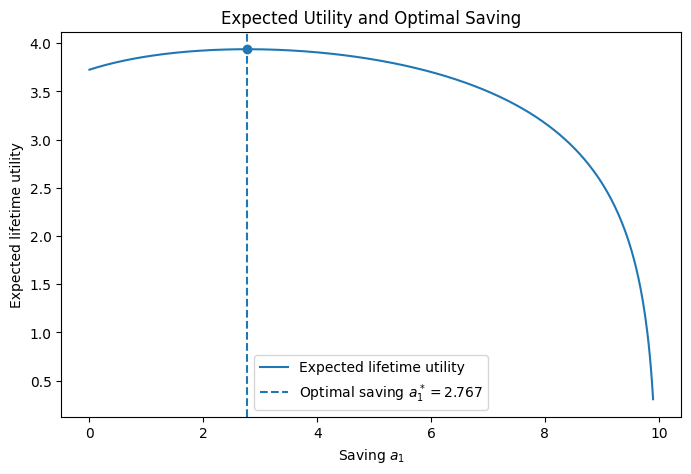

In [5]:
a_grid = np.linspace(0, 9.9, 500)
U_grid = np.array([expected_utility(a) for a in a_grid])

plt.figure(figsize=(8, 5))
plt.plot(a_grid, U_grid, label="Expected lifetime utility")
plt.axvline(a_star, linestyle="--", label=fr"Optimal saving $a_1^*={a_star:.3f}$")
plt.scatter([a_star], [expected_utility(a_star)], zorder=3)
plt.xlabel(r"Saving $a_1$")
plt.ylabel("Expected lifetime utility")
plt.title("Expected Utility and Optimal Saving")
plt.legend()
plt.show()


## 5. What does saving accomplish?

Saving reduces current consumption one-for-one:

$$
c_0=10-a_1.
$$

But it raises consumption tomorrow in **both** income states:

$$
c_1^{L}=1.02a_1+2,
\qquad
c_1^{H}=1.02a_1+10.
$$

This is the simplest form of **self-insurance**. The household cannot insure directly against the low-income state, but it can carry assets into the future so that consumption is less exposed to a bad income realization.


In [6]:
print("Optimal consumption allocation")
print("--------------------------------")
print(f"Today:             {c0_star:.3f}")
print(f"Tomorrow if Y1=2:  {c1_low:.3f}")
print(f"Tomorrow if Y1=10: {c1_high:.3f}")


Optimal consumption allocation
--------------------------------
Today:             7.233
Tomorrow if Y1=2:  4.822
Tomorrow if Y1=10: 12.822


## 6. Precautionary saving: compare with certain future income

The risky income distribution has mean

$$
E[Y_1]=6.
$$

To isolate the effect of **risk**, consider another household facing certain future income

$$
Y_1=6.
$$

Expected income is therefore identical in the two problems.

Under certainty, the household solves

$$
\max_{a_1}
\left\{
\log(10-a_1)
+\beta\log(1.02a_1+6)
\right\}.
$$

If optimal saving is higher under risky income than under certain income with the same mean, the difference is **precautionary saving**.


In [7]:
def utility_certain(a):
    c0 = y0 - a
    c1 = R * a + 6.0

    if c0 <= 0 or c1 <= 0:
        return -np.inf

    return np.log(c0) + beta * np.log(c1)

certain_result = minimize_scalar(
    lambda a: -utility_certain(a),
    bounds=(0.0, y0 - 1e-10),
    method="bounded"
)

a_certain = certain_result.x
precautionary_saving = a_star - a_certain

print(f"Optimal saving with risky income   = {a_star:.6f}")
print(f"Optimal saving with certain income = {a_certain:.6f}")
print(f"Difference                         = {precautionary_saving:.6f}")


Optimal saving with risky income   = 2.767008
Optimal saving with certain income = 1.855204
Difference                         = 0.911804


### Interpretation

Both households have exactly the same expected future income. The difference between their saving choices therefore does **not** come from a difference in expected income.

With log utility, marginal utility,

$$
u'(c)=\frac{1}{c},
$$

is especially high when consumption is low. The low-income outcome therefore matters disproportionately for the expected marginal value of future consumption. A$$ets are particularly valuable because they transfer resources into precisely the period in which the household might experience low income.

This additional demand for a$$ets in response to uncertainty is the **precautionary-saving motive**.


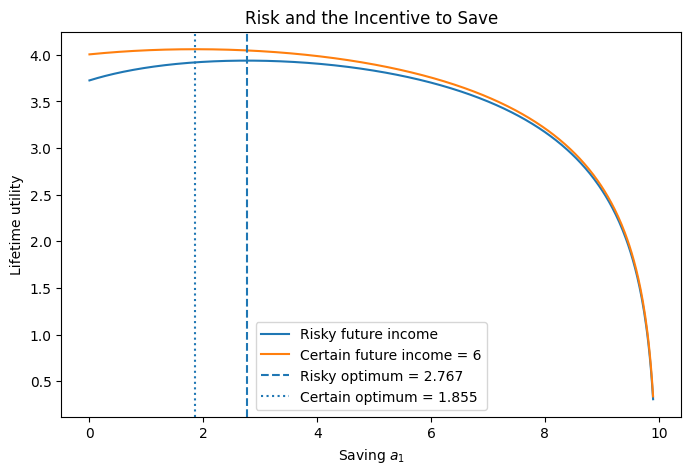

In [8]:
# Compare the two objective functions graphically
U_risky = np.array([expected_utility(a) for a in a_grid])
U_certain = np.array([utility_certain(a) for a in a_grid])

plt.figure(figsize=(8, 5))
plt.plot(a_grid, U_risky, label="Risky future income")
plt.plot(a_grid, U_certain, label="Certain future income = 6")
plt.axvline(a_star, linestyle="--", label=fr"Risky optimum = {a_star:.3f}")
plt.axvline(a_certain, linestyle=":", label=fr"Certain optimum = {a_certain:.3f}")
plt.xlabel(r"Saving $a_1$")
plt.ylabel("Lifetime utility")
plt.title("Risk and the Incentive to Save")
plt.legend()
plt.show()


## 7. The key lesson

This two-period example contains the basic economics of the income fluctuation problem.

1. **Income is uncertain.**
2. **Consumption is valuable to smooth across states and time.**
3. The household cannot directly insure the income shock.
4. Saving provides a way to **self-insure**.
5. With concave utility, a bad income realization has a large marginal-utility cost.
6. As a result, uncertainty can increase desired saving even when expected future income is unchanged.

In the infinite-horizon income fluctuation problem, the household repeatedly faces this same tradeoff. A$$ets become a buffer stock that households accumulate and draw down as income fluctuates.
